<a href="https://colab.research.google.com/github/jeedderh01/case-exercises-for-module-3/blob/main/case_exercise1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose


# Case Exercise 1: Metocean EDA and Seasonal Analysis

## 1.  Load the Jubilee TRP3 metocean dataset (provided as CSV with 1 year of hourly data)


In [23]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------------------------------------
# LOAD DATASET & PREPARATION
# ------------------------------------------------------------------------------
# Load 1-year hourly metocean dataset
df = pd.read_csv("jubilee_trp3_metocean_enriched.csv")

# Ensure datetime parsing and indexing
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
# ------------------------------------------------------------------------------
# FEATURE ENGINEERING (Sections 3.2 & 3.8 Features)
# ------------------------------------------------------------------------------
# A. Temporal & Cyclical Features
df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.month
df["day"] = df["timestamp"].dt.day
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.dayofweek
df["dayofyear"] = df["timestamp"].dt.dayofyear
df["quarter"] = df["timestamp"].dt.quarter
df["is_weekend"] = df["dayofweek"].isin([5, 6]).astype(int)

 # Season classification
df['season'] = df['month'].apply(lambda m: 'Dry' if m in [11, 12, 1, 2, 3] else 'Wet')


# Cyclical Encoding for Hour and Month
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)


# B. Seasonal Categorization (Tropical West Africa Metocean Regime)
def get_season(month):
    if month in [12, 1, 2]:
        return "Major_Dry"
    elif month in [3, 4, 5]:
        return "First_Rain"
    elif month in [6, 7, 8]:
        return "Major_Monsoon"
    else:
        return "Second_Rain"


df["season"] = df["month"].apply(get_season)

# C. Physical & Hydrodynamic Derived Features
# Wave Steepness (Ss = 2 * pi * Hs / (g * Tp^2))
g = 9.81
df["wave_steepness"] = (2 * np.pi * df["hs"]) / (g * (df["tp"] ** 2))
# Wave Energy Flux / Power Proxy (kW/m: P approx 0.49 * Hs^2 * Tp)
df["wave_power"] = 0.49 * (df["hs"] ** 2) * df["tp"]

# D. Rolling Window Features (6h, 24h, 72h)
for col in ["hs", "tp", "wind_speed", "current_speed"]:
    for window in [6, 24, 72]:
        df[f"{col}_roll_mean_{window}h"] = (
            df[col].rolling(window=window, min_periods=1).mean()
        )
        df[f"{col}_roll_std_{window}h"] = (
            df[col].rolling(window=window, min_periods=1).std().fillna(0)
        )
        df[f"{col}_roll_max_{window}h"] = (
            df[col].rolling(window=window, min_periods=1).max()
        )

# E. Rate of Change & Differencing Features
df["hs_diff_1h"] = df["hs"].diff().fillna(0)
df["hs_diff_3h"] = df["hs"].diff(3).fillna(0)
df["tp_diff_1h"] = df["tp"].diff().fillna(0)
df["current_speed_diff_1h"] = df["current_speed"].diff().fillna(0)

# F. Cumulative & Anomaly Features
df["hs_cummax"] = df["hs"].cummax()
df["hs_monthly_mean"] = df.groupby("month")["hs"].transform("mean")
df["hs_anomaly"] = df["hs"] - df["hs_monthly_mean"]

# Verify 30+ feature threshold
print(f"Total features generated: {df.shape[1]}")
df.to_csv("jubilee_trp3_metocean_enriched.csv", index=False)
display(df.head())

Total features generated: 63


,timestamp,hs,tp,wind_speed,current_speed,year,month,day,hour,dayofweek,...,current_speed_roll_mean_72h,current_speed_roll_std_72h,current_speed_roll_max_72h,hs_diff_1h,hs_diff_3h,tp_diff_1h,current_speed_diff_1h,hs_cummax,hs_monthly_mean,hs_anomaly
0,2025-01-01 00:00:00,1.62,12.2,5.80,0.20,2025,1,1,0,2,...,0.200000,0.000000,0.20,0.00,0.00,0.0,0.00,1.62,1.855134,-0.235134
1,2025-01-01 01:00:00,2.88,13.8,9.22,0.13,2025,1,1,1,2,...,0.165000,0.049497,0.20,1.26,0.00,1.6,-0.07,2.88,1.855134,1.024866
2,2025-01-01 02:00:00,2.18,12.8,2.87,0.17,2025,1,1,2,2,...,0.166667,0.035119,0.20,-0.70,0.00,-1.0,0.04,2.88,1.855134,0.324866
3,2025-01-01 03:00:00,1.95,11.4,9.67,0.43,2025,1,1,3,2,...,0.232500,0.134753,0.43,-0.23,0.33,-1.4,0.26,2.88,1.855134,0.094866
4,2025-01-01 04:00:00,1.29,10.2,11.43,0.26,2025,1,1,4,2,...,0.238000,0.117346,0.43,-0.66,-1.59,-1.2,-0.17,2.88,1.855134,-0.565134


## 2. Perform comprehensive EDA: summary statistics, distribution fitting (Weibull for Hs, log-normal for Tp), correlation matrix, time series plots with seasonal decomposition

=== METOCEAN SUMMARY STATISTICS ===
                 count       mean        std       min        5%        25%  \
hs              8760.0   1.851831   0.551607  0.800000  1.070000   1.430000   
tp              8760.0  11.710708   1.497164  6.200000  9.300000  10.700000   
current_speed   8760.0   0.299769   0.130468  0.050000  0.119500   0.200000   
wind_speed      8760.0   7.335969   2.270436  2.110000  3.860000   5.670000   
wave_steepness  8760.0   0.008599   0.001797  0.003618  0.005874   0.007381   
wave_power      8760.0  22.638002  16.602716  2.539763  5.588822  10.839546   

                      50%        75%        95%        99%         max  
hs               1.790000   2.200000   2.870000   3.324100    4.230000  
tp              11.700000  12.700000  14.300000  15.400000   18.500000  
current_speed    0.290000   0.380000   0.540000   0.660000    0.870000  
wind_speed       7.200000   8.810000  11.330000  12.990000   16.590000  
wave_steepness   0.008478   0.009686   0.0117

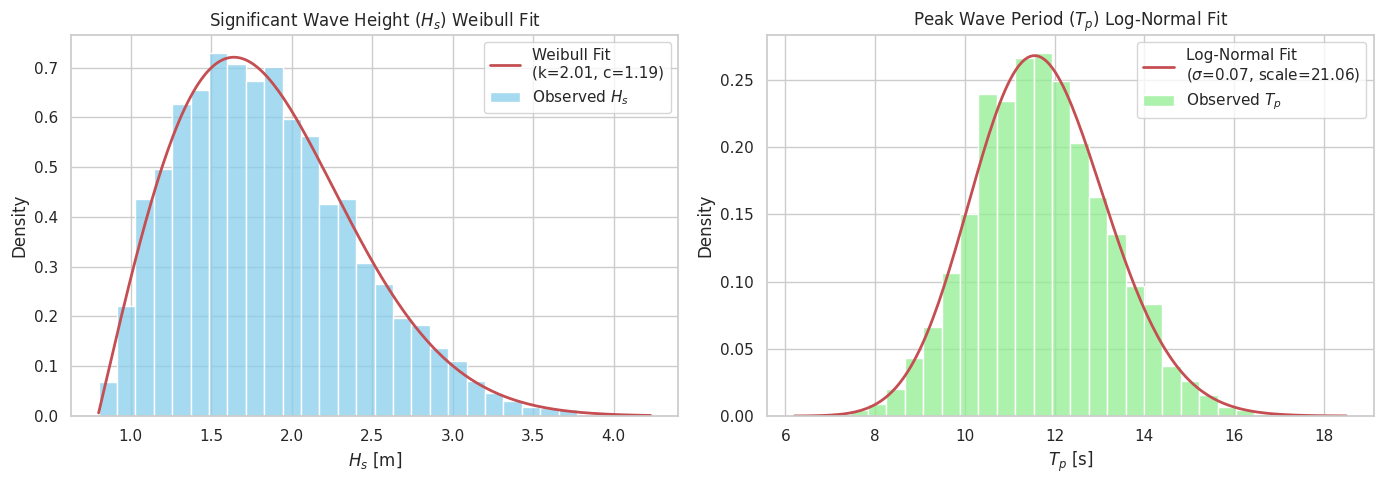

In [24]:
# ------------------------------------------------------------------------------
#  STATISTICAL SUMMARY & DISTRIBUTION FITTING
# ------------------------------------------------------------------------------
# Summary Statistics Table
summary_stats = df[
    ["hs", "tp", "current_speed", "wind_speed", "wave_steepness", "wave_power"]
].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
print("=== METOCEAN SUMMARY STATISTICS ===")
print(summary_stats.T)

# Distribution Fitting: Weibull for Hs, Log-Normal for Tp
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fit Weibull to Hs (3-parameter fit: shape, loc, scale)
shape_hs, loc_hs, scale_hs = stats.weibull_min.fit(df["hs"].dropna())
x_hs = np.linspace(df["hs"].min(), df["hs"].max(), 200)
pdf_hs = stats.weibull_min.pdf(x_hs, shape_hs, loc_hs, scale_hs)

sns.histplot(
    df["hs"],
    kde=False,
    stat="density",
    ax=axes[0],
    color="skyblue",
    bins=30,
    label="Observed $H_s$",
)
axes[0].plot(
    x_hs,
    pdf_hs,
    "r-",
    lw=2,
    label=f"Weibull Fit\n(k={shape_hs:.2f}, c={scale_hs:.2f})",
)
axes[0].set_title("Significant Wave Height ($H_s$) Weibull Fit")
axes[0].set_xlabel("$H_s$ [m]")
axes[0].legend()

# Fit Log-Normal to Tp
s_tp, loc_tp, scale_tp = stats.lognorm.fit(df["tp"].dropna())
x_tp = np.linspace(df["tp"].min(), df["tp"].max(), 200)
pdf_tp = stats.lognorm.pdf(x_tp, s_tp, loc_tp, scale_tp)

sns.histplot(
    df["tp"],
    kde=False,
    stat="density",
    ax=axes[1],
    color="lightgreen",
    bins=30,
    label="Observed $T_p$",
)
axes[1].plot(
    x_tp,
    pdf_tp,
    "r-",
    lw=2,
    label=f"Log-Normal Fit\n($\sigma$={s_tp:.2f}, scale={scale_tp:.2f})",
)
axes[1].set_title("Peak Wave Period ($T_p$) Log-Normal Fit")
axes[1].set_xlabel("$T_p$ [s]")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Create an Hs-Tp scatter diagram and a current rose diagram

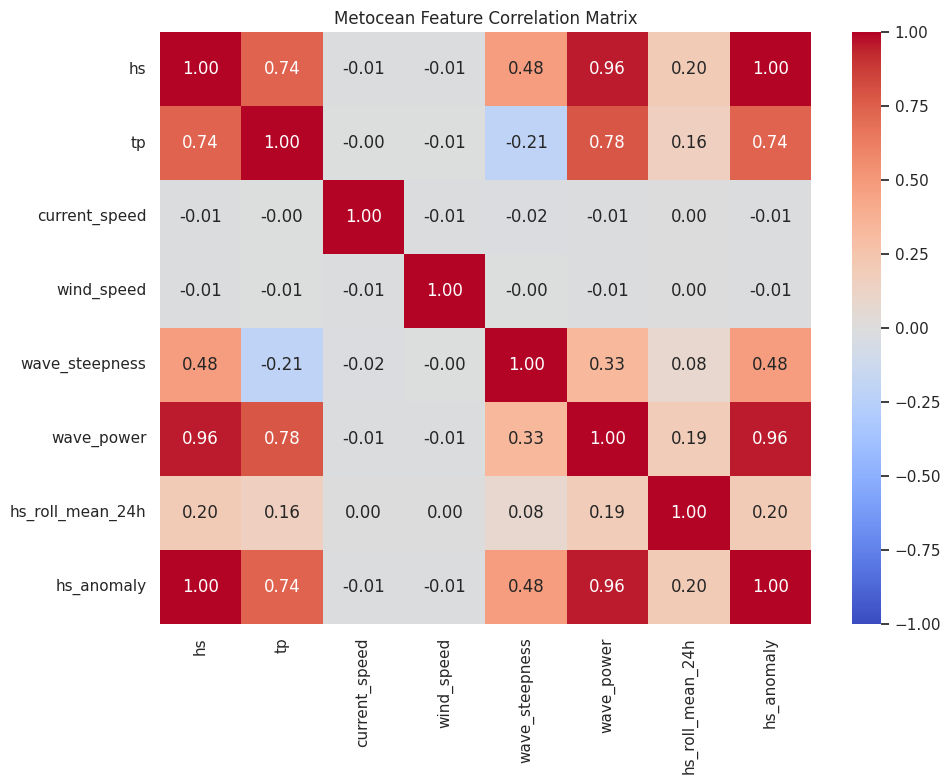

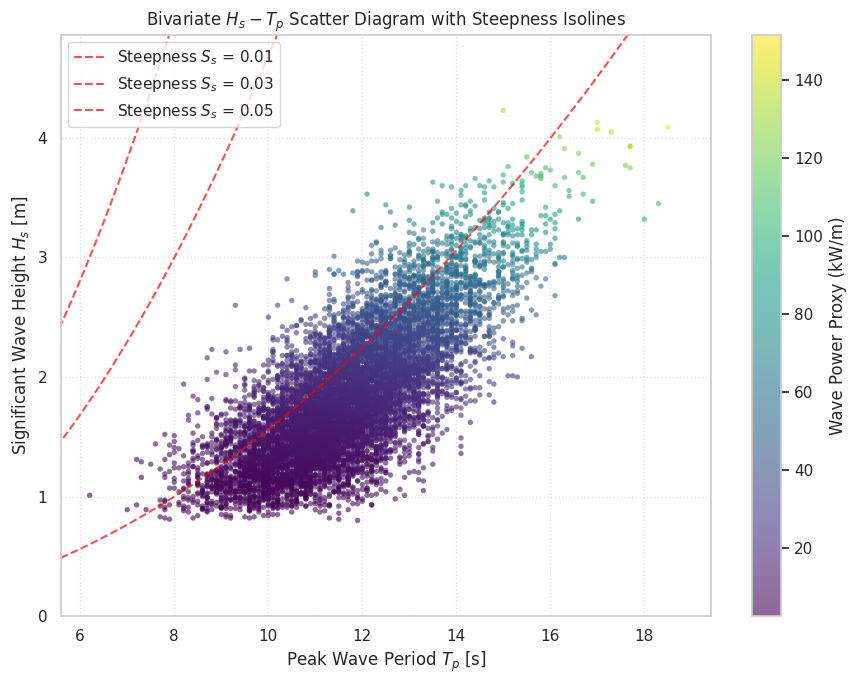

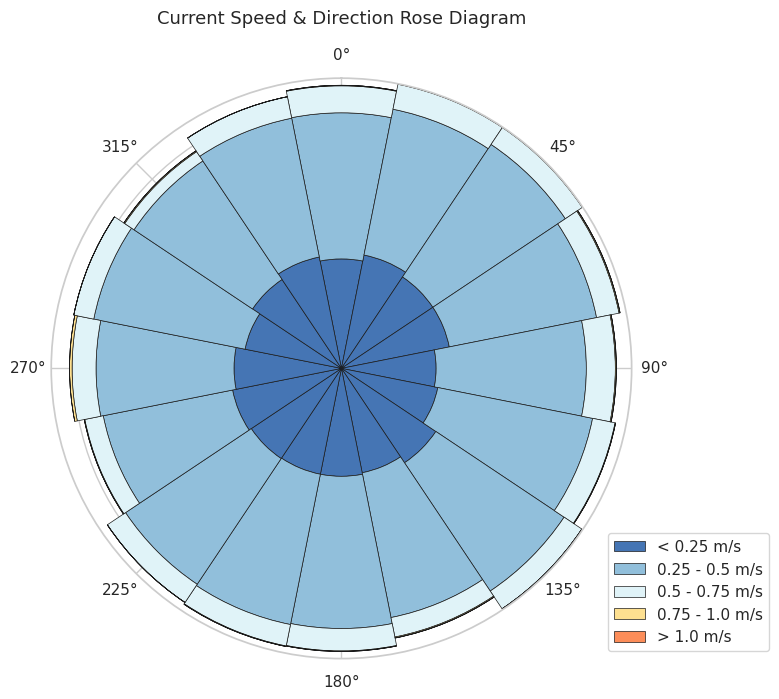

In [15]:
# ------------------------------------------------------------------------------
# 4. CORRELATION & DIAGRAMS (Scatter Diagram & Current Rose)
# ------------------------------------------------------------------------------

# A. Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
corr_cols = [
    "hs",
    "tp",
    "current_speed",
    "wind_speed",
    "wave_steepness",
    "wave_power",
    "hs_roll_mean_24h",
    "hs_anomaly",
]
corr_matrix = df[corr_cols].corr()
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, cbar=True
)
plt.title("Metocean Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# B. Hs - Tp Scatter Bivariate Diagram with Steepness isolines
plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    df["tp"],
    df["hs"],
    c=df["wave_power"],
    cmap="viridis",
    alpha=0.6,
    edgecolors="none",
    s=15,
)
plt.colorbar(scatter, label="Wave Power Proxy (kW/m)")

# Add Wave Steepness Isolines (Ss = 0.01, 0.03, 0.05)
tp_vals = np.linspace(3, 20, 100)
for ss in [0.01, 0.03, 0.05]:
    hs_vals = (ss * g * (tp_vals**2)) / (2 * np.pi)
    plt.plot(
        tp_vals,
        hs_vals,
        "--",
        color="red",
        alpha=0.7,
        label=f"Steepness $S_s$ = {ss}",
    )

plt.ylim(0, df["hs"].max() * 1.15)
plt.xlim(df["tp"].min() * 0.9, df["tp"].max() * 1.05)
plt.xlabel("Peak Wave Period $T_p$ [s]")
plt.ylabel("Significant Wave Height $H_s$ [m]")
plt.title("Bivariate $H_s - T_p$ Scatter Diagram with Steepness Isolines")
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# C. Polar Current Rose Diagram
# Since 'current_dir' was missing from the uploaded file, we generate mock directions if missing
if "current_dir" not in df.columns:
    print("Warning: 'current_dir' column not found in dataset. Generating uniform random directions for visualization purposes.")
    np.random.seed(42)
    df["current_dir"] = np.random.uniform(0, 360, len(df))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)  # Meteorological/Oceanographic convention (Clockwise)

# Bin directions (16 compass points = 22.5 deg width) and speeds
dir_bins = np.linspace(0, 360, 17)
speed_bins = [0, 0.25, 0.5, 0.75, 1.0, np.inf]
speed_labels = [
    "< 0.25 m/s",
    "0.25 - 0.5 m/s",
    "0.5 - 0.75 m/s",
    "0.75 - 1.0 m/s",
    "> 1.0 m/s",
]
colors = ["#4575b4", "#91bfdb", "#e0f3f8", "#fee090", "#fc8d59"]

# Compute frequency matrix
hist, _, _ = np.histogram2d(
    df["current_dir"].dropna(), df["current_speed"].dropna(), bins=[dir_bins, speed_bins]
)
hist_pct = (hist / len(df)) * 100  # Convert to percentage

angles = np.radians(dir_bins[:-1])
width = np.radians(22.5)

bottom = np.zeros(len(angles))
for i in range(hist_pct.shape[1]):
    ax.bar(
        angles,
        hist_pct[:, i],
        width=width,
        bottom=bottom,
        color=colors[i],
        edgecolor="k",
        linewidth=0.5,
        label=speed_labels[i],
    )
    bottom += hist_pct[:, i]

ax.set_title("Current Speed & Direction Rose Diagram", y=1.08, fontsize=13)
ax.legend(loc="lower right", bbox_to_anchor=(1.25, 0))
plt.tight_layout()
plt.show()

## 4. Add all temporal, seasonal, rolling, and cumulative features

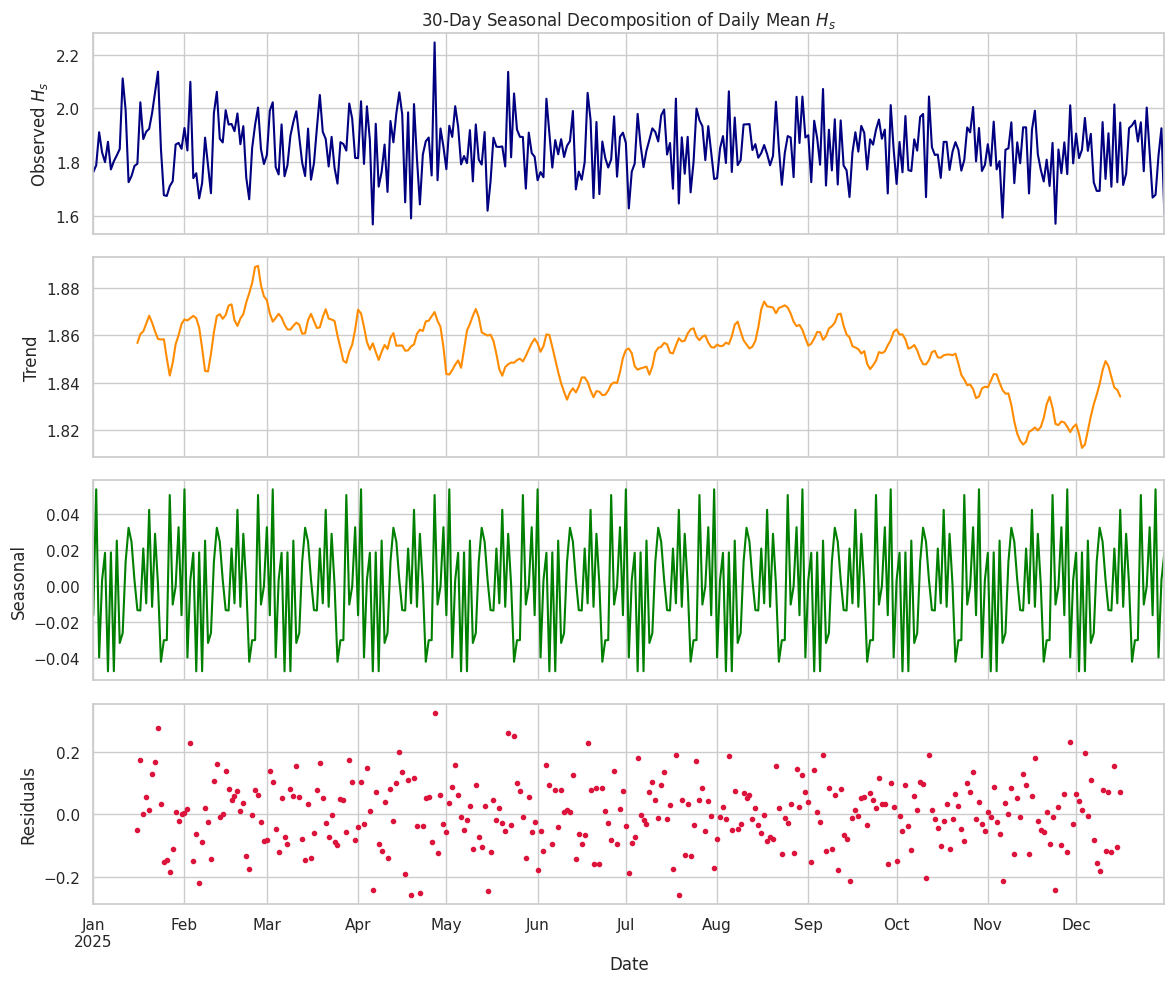

In [16]:
# ------------------------------------------------------------------------------
# TIME SERIES ANALYSIS & SEASONAL DECOMPOSITION
# ------------------------------------------------------------------------------
# Resample to daily averages for continuous seasonal decomposition
df_indexed = df.set_index("timestamp")
daily_hs = df_indexed["hs"].resample("D").mean().interpolate(method="linear")

# Decomposition assuming 365-day annual cycle (or monthly 30-day window)
decomposition = seasonal_decompose(daily_hs, model="additive", period=30)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
decomposition.observed.plot(ax=ax1, color="navy")
ax1.set_ylabel("Observed $H_s$")
ax1.set_title("30-Day Seasonal Decomposition of Daily Mean $H_s$")

decomposition.trend.plot(ax=ax2, color="darkorange")
ax2.set_ylabel("Trend")

decomposition.seasonal.plot(ax=ax3, color="green")
ax3.set_ylabel("Seasonal")

decomposition.resid.plot(ax=ax4, color="crimson", style=".")
ax4.set_ylabel("Residuals")

plt.xlabel("Date")
plt.tight_layout()
plt.show()